# Bayesian Regression with a Kink

## Disclaimer

I thought I would do the unusual with this post.  Instead of Claude AI writing the code, in this  post, a human (me) wrote the code, and Claude wrote the words on English!

## Introduction

More adventures in Bayes-land!

In my [last post](https://coolum001.github.io/bayeswt.html) I fitted a straight line to my diet weight data using PyMC, and I finished by saying that my next step would be to look at models with kinks in the fitted line. This is that post.

Looking at the raw data (see below), it is pretty clear that a single straight line doesn't tell the whole story. For the first five months or so, my weight came down at a fairly steady rate, but towards the end the weight loss seems to stall. The data was originally explored (in a non-Bayesian way) in an [earlier post](https://coolum001.github.io/funminim.html).

So the questions I wanted to ask were:

- Is there really a change in the rate of weight loss, or am I just seeing patterns in the noise?
- If there is a change, *when* did it happen?
- What was the rate of weight loss before and after the change?

The nice thing about the Bayesian approach is that the *time* of the change (the kink, or inflexion point) can just be another parameter in the model, and we get a probability distribution for it, the same as for the slopes and intercept. In a classical least-squares approach, finding the best breakpoint is a bit more awkward (you typically have to search over candidate breakpoints, and getting an uncertainty for the breakpoint is harder).

---

## Implementation

### Imports

These are the same imports as in my last post. In brief, the less common libraries are:

- **ArviZ**: exploratory analysis of Bayesian models: diagnostics, summaries, and plots
- **PyMC**: a probabilistic programming library, used to build Bayesian models and fit them using Markov chain Monte Carlo (MCMC) sampling
- **PyTensor**: the library that PyMC uses under the covers to define and evaluate the mathematical expressions in a model
- **xarray**: labelled, multi-dimensional arrays (the sampling results from PyMC come back as `xarray` objects)

`pytensor` isn't actually used directly in this notebook; it is a hold-over from my last post, where I had to configure it to work around a problem in my environment.

In [1]:
import pathlib

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor
import xarray as xr

### Load dataset

The data lives in the same Excel spreadsheet I used for my last post. The spreadsheet was designed for humans, not for Python, so we have to tell `pandas` exactly where the data is:

- `sheet_name` - the data is in the `Data Entry` worksheet
- `usecols=[3, 4]` - we only want the day number and weight columns
- `skiprows=2` - skip the title and header rows at the top of the sheet
- `nrows=141` - there are 141 weigh-ins; this stops us reading any summary rows below the data
- `names` - give the columns sensible names, so we can say `df.day` and `df.weight`

In [2]:
path = pathlib.Path("data/diet_results.xlsx")
df = pd.read_excel(
    path,
    sheet_name="Data Entry",
    usecols=[3, 4],
    skiprows=2,
    nrows=141,
    names=["day", "weight"],
)

### Visualize dataset

A quick and dirty plot of the raw data, just to check that it has loaded correctly, and to get a feel for its shape.

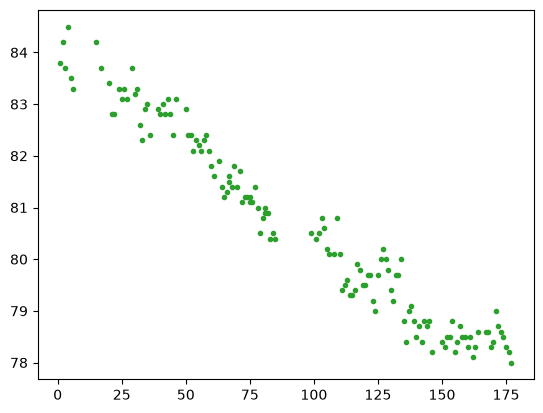

In [3]:
plt.plot(df.day, df.weight, "C2.")

Points to note:

- There is a gap at around day 85 to day 100, where I wasn't recording my weight. This isn't a problem for regression: we only fit to the days we have
- The day-to-day scatter is about plus or minus half a kilogram, which is typical for daily weigh-ins (what you ate and drank yesterday matters!)
- By eye, the weight loss is steady up to about day 150, and then seems to flatten out

That last point is what we are going to test.

---

### Build and run kinked linear model

The model is a "hinge" or "broken stick" regression. The fitted line has one slope before the inflexion point `tau`, and a different slope after it, and the two line segments join up at `tau` (i.e. the line is continuous, but its slope is not).

The trick for writing this as a single formula is the `max(0, day - tau)` term:

$$
weight = intercept + slope1 \times day + (slope2 - slope1) \times \max(0, day - tau)
$$

- Before the inflexion point (`day < tau`), the `max(...)` term is zero, so the line is just `intercept + slope1 * day`
- After the inflexion point, the `max(...)` term grows by one for each day, so the slope becomes `slope1 + (slope2 - slope1)`, which is just `slope2`
- At `day = tau`, both formulas give the same value, so there is no jump in the line

To start, we specify our priors:

- `intercept`: my weight at day zero. I know I started at around 85 kg, but I gave it a very wide standard deviation (100 kg!) so that the data, not my guess, decides the value
- `slope1`: the rate of weight loss (kg per day) before the kink. I expect it to be negative (I *was* on a diet), so I centred it on -0.5, but again with a large spread
- `slope2`: the rate of weight change after the kink. I centred this on zero, because I didn't want to presuppose whether the weight loss continued, stopped, or reversed
- `error_sd`: the standard deviation of the day-to-day scatter about the line. This must be positive, so I used a `HalfCauchy` distribution, which is a common choice for scale parameters: it is fairly flat for small values, but has a long tail in case the noise is larger than expected
- `tau`: the day of the inflexion point. I used a `Uniform` prior between day 100 and day 175. Looking at the plot above, the kink (if any) is clearly in the second half of the data. Restricting `tau` also stops the sampler trying to put the kink right at the end of the data, where there would be too few points after it to estimate `slope2`

Then:

- `w_err0` is the fitted line, without any noise. Wrapping it in `pm.Deterministic` means that PyMC will save its values for every sample, so we can look at them later
- `w_pred` is the likelihood: the observed weights are assumed to be normally distributed about the fitted line, with standard deviation `error_sd`

Finally we call `pm.sample` to draw 2,000 samples from the posterior (per chain, after the default tuning steps). The output shows that PyMC chose the `nutpie` implementation of the NUTS sampler.

The `threadpoolctl` warning below is about two different OpenMP libraries being loaded at the same time. The warning says the problems are mainly seen on Linux; I am on Windows, and haven't had any crashes, so I have ignored it.

In [4]:
with pm.Model() as model:

    intercept = pm.Normal("intercept", mu=85, sigma=100)
    slope1 = pm.Normal("slope1", mu=-0.5, sigma=10)
    slope2 = pm.Normal("slope2", mu=0, sigma=10)
    error_sd = pm.HalfCauchy("error_sd", beta=10)

    # Unknown inflection point (constrained within the range of x)
    tau = pm.Uniform("tau", lower=100, upper=175)

    w_err0 = pm.Deterministic(
        "w_err0",
        intercept
        + slope1 * df.day.values
        + (slope2 - slope1) * pm.math.maximum(0, df.day.values - tau),
    )
    w_pred = pm.Normal("w_pred", mu=w_err0, sigma=error_sd, observed=df.weight.values)
    idata = pm.sample(draws=2000)
# end

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [intercept, slope1, slope2, error_sd, tau]


Output()

Visualize the model (looks OK). This is a good check that the model structure is what I intended: the five random variables all feed into `w_err0` and then into the observed `w_pred` (141 observations).

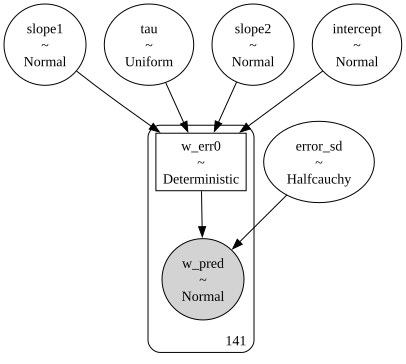

In [5]:
pm.model_to_graphviz(model)

### Check for sampling problems

Automatically review the sampling run for problems - the moment of truth! As I said in an [earlier post](https://coolum001.github.io/bayeshsk2.html), I strongly recommend always running `diagnose()`.

I was a little worried that the `max()` function in the model would cause problems, because it has a sharp corner, and the NUTS sampler relies on smooth gradients. But we got a clean bill of health.

In [6]:
problems = az.diagnose(idata)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


The energy plot is another visual check of the sampler. If the two distributions (the marginal energy, and the energy transition) look roughly the same, the sampler has been able to explore the whole posterior. They match well (all OK).

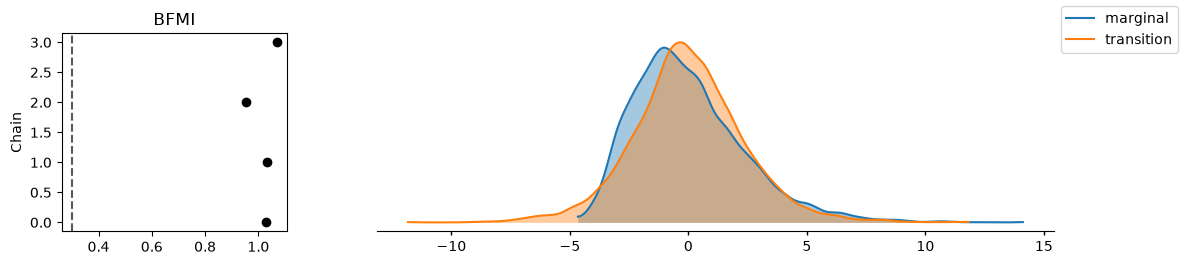

In [7]:
pc = az.plot_energy(
    idata,
)

---

### Examine the results

First a summary of the parameters of the line. Note that the ArviZ version I am using now reports an 89% *equal-tailed interval* (`eti89_lb` and `eti89_ub`), rather than the 94% highest density interval that older versions reported.

Points to note:

- `slope1` is about -0.0375 kg per day, with a narrow interval: there is no doubt that I was losing weight in the first part of the diet
- `slope2` is about zero, and its 89% interval comfortably includes zero (-0.014 to +0.016): after the kink, my weight was essentially flat
- `tau` (the inflexion point) is about day 150, give or take 5 days
- `r_hat` is 1.00 for all parameters, and the effective sample sizes (`ess_bulk`, `ess_tail`) are in the thousands, which confirms what `diagnose()` told us

In [8]:
az.summary(idata, var_names=["intercept", "slope1", "slope2", "tau"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,84.133,0.068,84,84,2672,3452,1.00,0.0013,0.00086
slope1,-0.03753,0.00075,-0.039,-0.036,2578,3354,1.00,1.5e-05,1e-05
slope2,-0.0004,0.01,-0.014,0.017,2763,2308,1.00,0.00021,0.00021
tau,150.8,4.6,140,160,2578,2285,1.00,0.09,0.069


Plot the posterior distributions of the parameters. They all look reasonably smooth, and unimodal (there is only one hump). `tau` is the most interesting: I was half expecting several competing inflexion points, but the data seems to settle on one.

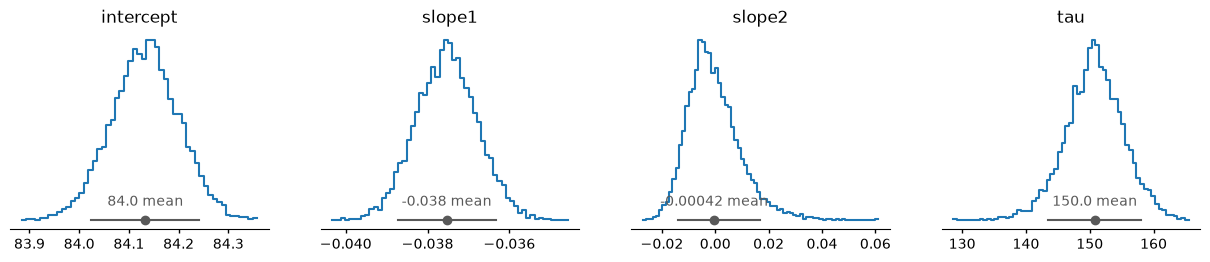

In [9]:
az.plot_dist(idata, var_names=["intercept", "slope1", "slope2", "tau"], kind="hist")

### Plot the fitted line

To draw the fitted line, I take the mean of each parameter from the posterior summary. `az.summary` returns a `pandas` DataFrame, so we can use `.loc` to pick out the values we want.

In [10]:
smry = az.summary(idata, var_names=["intercept", "slope1", "slope2", "tau"])

intercept_m = float(smry.loc["intercept", "mean"])
slope1_m = float(smry.loc["slope1", "mean"])
slope2_m = float(smry.loc["slope2", "mean"])
tau_m = float(smry.loc["tau", "mean"])

In [11]:
intercept_m, slope1_m, slope2_m, tau_m

(84.13308161299125,
 -0.037532382303725575,
 -0.0004216872222174035,
 150.77078895500907)

Now compute the fitted weight for each day, using the same formula as the model, but with plain Python numbers (and the Python built-in `max`, rather than `pm.math.maximum`).

In [12]:
pred = [
    intercept_m + d * slope1_m + (slope2_m - slope1_m) * max(0, d - tau_m)
    for d in df.day.values
]

Plot the raw data, and the fitted line. The kink at day 150 is clear, and the fit looks plausible.

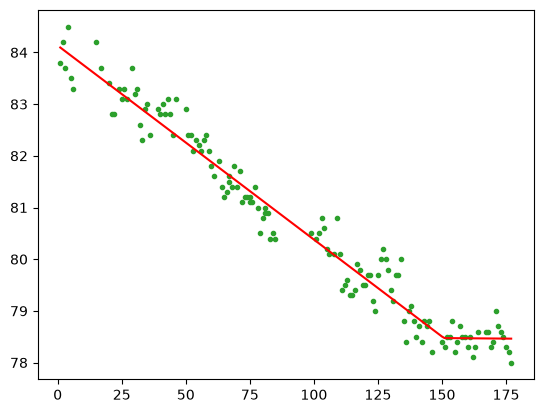

In [13]:
plt.plot(df.day, df.weight, "C2.")
plt.plot(df.day, pred, "-r")

A rate of -0.0375 kg per day is hard to visualize, so I converted it to the number of days it took to lose one kilogram.

In [14]:
equation = f"weight = {intercept_m:.1f} - days / {(1/abs(slope1_m)):.1f}"
equation

'weight = 84.1 - days / 26.6'

So, before the kink, I lost 1 kg every 26.6 days or so (a little over 1 kg per month). Over the 150 days before the kink that adds up to about 5.6 kg. Slow but steady!

---

### Compare slopes before and after inflexion point

The summary table gives us means and intervals, but I wanted to see the full distributions of the two slopes side-by-side.

First, let's look at the `InferenceData` object returned by the sampler. With the latest version of ArviZ, this is now an `xarray` `DataTree`. The `posterior` group has a value for each parameter for each chain (4) and each draw (2,000). Note that `w_err0` also has a `w_err0_dim_0` dimension of size 141, because there is a fitted value for each day in the dataset.

In [15]:
idata

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:       (chain: 4, draw: 2000, w_err0_dim_0: 141)
│       Coordinates:
│         * chain         (chain) int64 32B 0 1 2 3
│         * draw          (draw) int64 16kB 0 1 2 3 4 5 ... 1995 1996 1997 1998 1999
│         * w_err0_dim_0  (w_err0_dim_0) int64 1kB 0 1 2 3 4 5 ... 136 137 138 139 140
│       Data variables:
│           intercept     (chain, draw) float64 64kB 84.13 84.13 84.14 ... 84.15 84.2
│           slope1        (chain, draw) float64 64kB -0.03782 -0.03727 ... -0.038
│           slope2        (chain, draw) float64 64kB 0.005344 0.005 ... -0.0004017
│           error_sd      (chain, draw) float64 64kB 0.3327 0.3586 ... 0.3354 0.323
│           tau           (chain, draw) float64 64kB 150.2 154.1 149.7 ... 148.9 150.1
│           w_err0        (chain, draw, w_err0_dim_0) float64 9MB 84.09 84.05 ... 78.48
│       Attributes:
│           created_at:                 2026-11-10T05:53:15.419434+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              0.35756874084472656
│           tuning_steps:               400
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 2000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 16kB 0 1 2 3 ... 1996 1997 1998 1999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 64kB 3 2 3 3 3 ... 2 3 3 2 3
│           maxdepth_reached          (chain, draw) bool 8kB False False ... False False
│           step_size                 (chain, draw) float64 64kB 0.4652 0.518 ... 0.5443
│           transformation_update_id  (chain, draw) int64 64kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 64kB 0.4816 ... 0.4989
│           mean_tree_accept          (chain, draw) float64 64kB 0.9629 ... 0.9032
│           ...                        ...
│           fisher_distance           (chain, draw) float64 64kB 4.563 2.219 ... 7.853
│           transformation_index      (chain, draw) int64 64kB 339 339 339 ... 339 339
│           diverging                 (chain, draw) bool 8kB False False ... False False
│           divergence_draw           (chain, draw) uint64 64kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) object 64kB None None ... None None
│           divergence_energy_error   (chain, draw) float64 64kB nan nan nan ... nan nan
│       Attributes:
│           created_at:                  2026-11-10T05:53:15.401014+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.0
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /constant_data
│       Attributes:
│           created_at:                 2026-11-10T05:53:15.413415+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
└── Group: /observed_data
        Dimensions:       (w_pred_dim_0: 141)
        Coordinates:
          * w_pred_dim_0  (w_pred_dim_0) int64 1kB 0 1 2 3 4 5 ... 136 137 138 139 140
        Data variables:
            w_pred        (w_pred_dim_0) float64 1kB 83.8 84.2 83.7 ... 78.3 78.2 78.0
        Attributes:
            created_at:                 2026-11-

Pull out the samples for each slope. I took the mean over the four chains, which leaves me with one value per draw (2,000 values) to histogram.

In [16]:
slope1_da = idata["posterior"]["slope1"]
slope1_dr = slope1_da.mean(dim=["chain"])

slope2_da = idata["posterior"]["slope2"]
slope2_dr = slope2_da.mean(dim=["chain"])

Plot the histograms of the two slopes, with a vertical line at zero slope (no weight change).

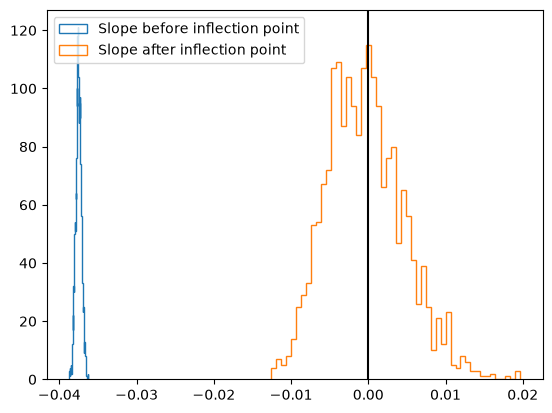

In [17]:
plt.hist(
    slope1_dr,
    histtype="step",
    bins=50,
    label="Slope before inflection point",
)

plt.hist(
    slope2_dr,
    histtype="step",
    bins=50,
    label="Slope after inflection point",
)
plt.axvline(0, color="k")
plt.legend()

The two distributions don't overlap at all. Before the inflexion point, the slope is tightly clustered around -0.0375. After the inflexion point, the slope distribution is much wider (we only have about 25 days of data after day 150 to estimate it), but is centred close to zero, with zero well inside the distribution.

So I think we can say with some confidence that my weight loss did stop at about day 150. Whether that was my body hitting some natural floor, or me getting slack, is left as an exercise for the reader!

---

### Final graphic

For the final graphic, I want to show the raw data, the fitted line, a band showing where we would expect individual weigh-ins to fall, and the uncertainty in the position of the inflexion point.

First, get the mean of the error standard deviation (over all draws and chains). This is the typical day-to-day scatter of my weight about the fitted line.

In [18]:
error_sds = float(idata["posterior"]["error_sd"].mean(("draw", "chain")))

In [19]:
error_sds

0.34877665652569784

Just to check, the summary gives the same value, about 0.35 kg (i.e. most daily weigh-ins are within about plus or minus 0.7 kg of the line).

In [20]:
az.summary(idata, var_names=["error_sd"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
error_sd,0.3488,0.0215,0.32,0.39,6539,5343,1.00,0.00027,0.00026


Get the samples for the inflexion point `tau`, again averaging over the chains.

In [21]:
tau_da = idata["posterior"]["tau"]
tau_dr = tau_da.mean(dim=["chain"])

Now draw the final graphic. Points to note:

- The upper and lower bands are 1.96 standard deviations (`error_sd`) above and below the fitted line. If the model is right, about 95% of the daily weigh-ins should fall between them. Note this band only reflects the day-to-day noise, not the uncertainty in the fitted line itself; the parameters are so tightly constrained that I think this is a reasonable shortcut
- The distribution of the inflexion point is drawn on a second y axis (`twinx`), sharing the same x axis (days). The y values of this histogram have no real meaning on the weight scale, so I removed the tick labels on the right-hand axis
- I set `alpha` on the raw data and the bands, so that the fitted line and the inflexion point stand out

Text(0.5, 1.0, 'Weight loss model - discontinuous slope')

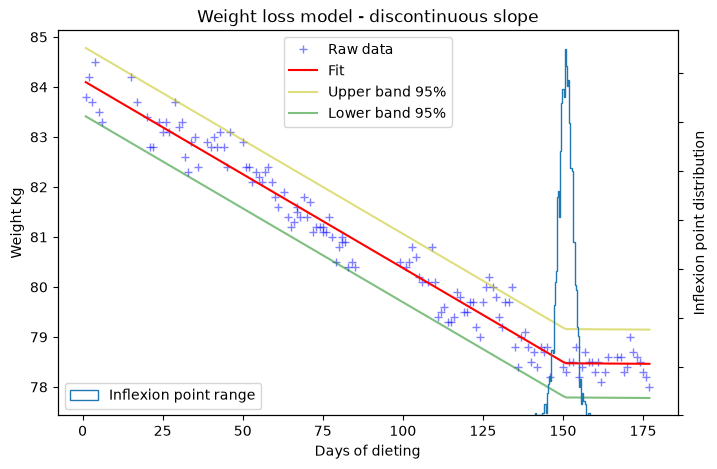

In [22]:
fig, ax1 = plt.subplots(figsize=(8, 5))

ax1.plot(
    df.day,
    df.weight,
    "+b",
    label="Raw data",
    alpha=0.5, 
)
ax1.plot(
    df.day,
    pred,
    "-r",
    label="Fit",
)

ax1.plot(
    df.day,
    [p + 1.96 * error_sds for p in pred],
    "-y",
    label="Upper band 95%",
    alpha=0.5, 
)

ax1.plot(
    df.day,
    [p - 1.96 * error_sds for p in pred],
    "-g",
    label="Lower band 95%",
    alpha=0.5, 
)

ax2 = ax1.twinx()
ax2.hist(
    tau_dr,
    bins=50,
    label="Inflexion point range",
    histtype="step",
    density=True,
)

ax1.set_xlabel("Days of dieting")
ax1.set_ylabel("Weight Kg")
ax2.set_ylabel("Inflexion point distribution")
ax2.set_yticklabels([])


ax1.legend(loc="upper center")
ax2.legend(loc="lower left")
ax1.set_title("Weight loss model - discontinuous slope")

The final graphic tells the story quite well: steady weight loss for about 150 days, then a plateau, with the inflexion point fairly tightly pinned down (somewhere between day 140 and day 160).

---

## Conclusion

Adding a kink to the linear model turned out to be surprisingly easy in PyMC: one extra parameter for the inflexion point, and a `max()` term in the formula for the line. I was worried that the sharp corner would upset the NUTS sampler, but it handled the model with no problems at all.

What I really like about this approach is that the inflexion point gets its own probability distribution, just like the slopes. With classical regression, I would have had to search over possible breakpoints, and then I would still not have had a good feel for how uncertain the breakpoint was.

As for the diet: I lost about 1 kg a month for five months, and then stopped losing weight. The Bayesian analysis just confirms what my bathroom scales were telling me at the time!

---

## Reproducability

### Notebook version status

In [23]:
%load_ext watermark

In [24]:
%watermark

Last updated: 2026-11-10T15:53:19.665746+10:00

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

Compiler    : MSC v.1944 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 170 Stepping 4, GenuineIntel
CPU cores   : 22
Architecture: 64bit



In [25]:
%watermark -h -iv -co

conda environment: bayes_env

Hostname: INSPIRON16

arviz     : 1.3.0
matplotlib: 3.11.1
numpy     : 2.4.6
pandas    : 3.0.5
pymc      : 6.3.1
pytensor  : 3.3.0
xarray    : 2026.7.0

